
# Classification Models using Machine Learning

## Objective
Build and compare two classification models:
1. Logistic Regression
2. Decision Tree Classifier

## Dataset
Iris Flower Dataset from Scikit-learn.

## Machine Learning Workflow
1. Load and explore the dataset.
2. Separate features and target.
3. Split the data into training and testing sets.
4. Train a Logistic Regression model.
5. Train a Decision Tree model.
6. Compare both models using accuracy.
7. Record observations and conclusions.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target

display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSpecies distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Species distribution:
species
0    50
1    50
2    50
Name: count, dtype: int64


In [4]:
# Input features
X = df.drop("species", axis=1)

# Target variable
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training target: (120,)
Testing target: (30,)


In [6]:
# Create the Logistic Regression model
log_model = LogisticRegression(max_iter=1000)

# Train the model
log_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [7]:
# Predict species using Logistic Regression
y_pred_log = log_model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    "Actual Species": y_test.values,
    "Predicted Species": y_pred_log
})

display(results.head(10))

,Actual Species,Predicted Species
0,0,0
1,2,2
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,2,2
9,1,1


In [8]:
# Calculate accuracy
log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", log_accuracy)
print("Accuracy in percentage:", log_accuracy * 100, "%")

Logistic Regression Accuracy: 0.9666666666666667
Accuracy in percentage: 96.66666666666667 %


In [9]:
# Create the Decision Tree model
tree_model = DecisionTreeClassifier(random_state=42)

# Train the model
tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [10]:
# Predict species using Decision Tree
y_pred_tree = tree_model.predict(X_test)

# Display actual and predicted values
tree_results = pd.DataFrame({
    "Actual Species": y_test.values,
    "Predicted Species": y_pred_tree
})

display(tree_results.head(10))

,Actual Species,Predicted Species
0,0,0
1,2,2
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,2,2
9,1,1


In [11]:
# Calculate Decision Tree accuracy
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", tree_accuracy)
print("Accuracy in percentage:", tree_accuracy * 100, "%")

Decision Tree Accuracy: 0.9333333333333333
Accuracy in percentage: 93.33333333333333 %


In [12]:
# Create accuracy comparison table
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [log_accuracy, tree_accuracy]
})

comparison["Accuracy (%)"] = comparison["Accuracy"] * 100

display(comparison)

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.966667,96.666667
1,Decision Tree,0.933333,93.333333


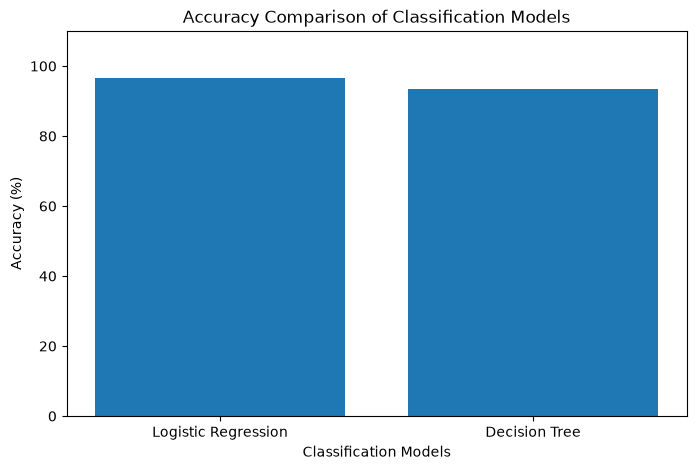

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(comparison["Model"], comparison["Accuracy (%)"])

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)

plt.show()

## Observations

1. Logistic Regression was trained successfully on the Iris dataset.
2. Decision Tree Classifier was also trained successfully.
3. Both models were evaluated using the same testing dataset.
4. Their performance was compared using accuracy scores.
5. The model with the higher accuracy performed better on this test dataset.

## Conclusion

In this task, I learned the basics of classification problems and implemented two classification algorithms: Logistic Regression and Decision Tree Classifier.

I compared both models using accuracy and understood how machine learning models can predict different categories based on input features.

The experiment helped me understand model training, prediction, testing, and performance evaluation.

In [14]:
# Logistic Regression classification report
print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, y_pred_log, target_names=iris.target_names))

# Decision Tree classification report
print("DECISION TREE REPORT")
print(classification_report(y_test, y_pred_tree, target_names=iris.target_names))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

DECISION TREE REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



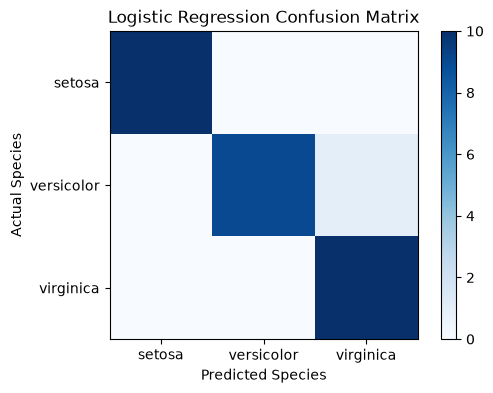

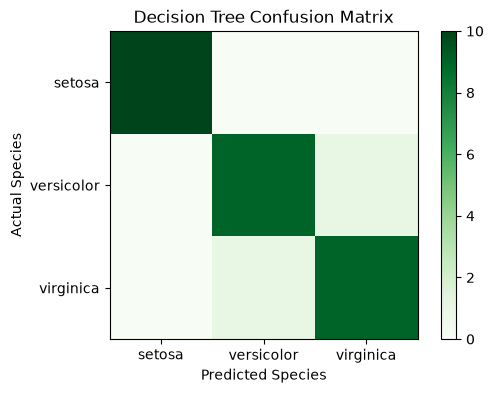

In [15]:
# Create confusion matrices
cm_log = confusion_matrix(y_test, y_pred_log)
cm_tree = confusion_matrix(y_test, y_pred_tree)

# Plot Logistic Regression confusion matrix
plt.figure(figsize=(6, 4))
plt.imshow(cm_log, cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)
plt.colorbar()
plt.show()

# Plot Decision Tree confusion matrix
plt.figure(figsize=(6, 4))
plt.imshow(cm_tree, cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)
plt.colorbar()
plt.show()